# Notebook 2 — Baseline : régression linéaire sur des descripteurs physiques

**Objectif.** Obtenir un score de référence simple avant le réseau de neurones. Si le réseau ne fait pas nettement mieux, sa complexité n'est pas justifiée.

**Pourquoi une régression ?** Les cibles (HLC_mit, HLC_ext en W/K ; τ_b, τ_n, τ_inf en h) sont des nombres continus : on estime une valeur, on ne choisit pas une catégorie.

**Pourquoi linéaire ?** Solution exacte par moindres carrés, sans hyperparamètre, et interprétable. Le travail « intelligent » est dans le choix des descripteurs ; la régression ne fait que les pondérer.

**Organisation.** Le code est dans les modules (`thermal_id.features`, `thermal_id.baseline`, `thermal_id.metrics`) ; ce notebook les importe et présente la démarche et les résultats.

| Section | Contenu |
|---|---|
| 1 | Chargement des descripteurs (train 1–16, validation 17–18) |
| 2 | Descripteurs de forme : pourquoi ils ne suffisent pas |
| 3 | Descripteurs d'identification : réponse indicielle par simulation |
| 4 | Ajustement et résultats sur la validation |
| 5 | Où le modèle se trompe |
| 6 | Contrôle : quel plafond à signal U fixé ? |
| 7 | Conclusions |

Le jeu de test (batches 19–20) n'est **pas** utilisé ici : il est réservé à l'évaluation finale du modèle retenu.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from thermal_id.baseline import LinearBaseline, batch_features, run
from thermal_id.data import RAW_TARGETS, CompactBatch, Normalizer
from thermal_id.features import ALL_FEATURE_NAMES, FEATURE_NAMES, MODE_TAUS_MIN, STEP_FEATURE_NAMES

from thermal_id.paths import PROCESSED_DIR as PROCESSED, RESULTS_DIR as RESULTS

manifest = json.loads((PROCESSED / "manifest.json").read_text(encoding="utf-8"))
norm = Normalizer.load(PROCESSED / "normalizer.json")
train_ids, val_ids = manifest["splits"]["train"], manifest["splits"]["val"]

## 1. Chargement des descripteurs

Chaque simulation (T_int, U) de 480 pas est résumée en 36 nombres (`thermal_id.features.all_features`). Ils sont calculés une fois par fichier et mis en cache (`data/processed/features_XX.pt`, environ 75 s la première fois) : on ne charge jamais les 800 000 courbes du train en même temps.

In [2]:
feats = {k: batch_features(PROCESSED, k) for k in train_ids + val_ids}
val = {key: torch.cat([feats[k][key] for k in val_ids]) for key in ("X", "y", "min_duration_h", "p_on")}
Xv = pd.DataFrame(val["X"].numpy(), columns=ALL_FEATURE_NAMES)
yv = pd.DataFrame(val["y"].numpy(), columns=RAW_TARGETS)
targets_t = yv.copy()
for c in ("tau_b", "tau_n", "tau_inf"):
    targets_t[c] = np.log(targets_t[c])
targets_t.columns = ["HLC", "HLC_mit", "HLC_ext", "log tau_b", "log tau_n", "log tau_inf"]
print("train :", sum(len(feats[k]["X"]) for k in train_ids), "simulations ; validation :", len(Xv))
print(len(ALL_FEATURE_NAMES), "descripteurs :", len(FEATURE_NAMES), "de forme +", len(STEP_FEATURE_NAMES), "d'identification")

train : 800000 simulations ; validation : 100000
36 descripteurs : 18 de forme + 18 d'identification


## 2. Descripteurs de forme : pourquoi ils ne suffisent pas

Premiers descripteurs, guidés par l'EDA : part du temps chauffé, montées de température (`rise_60`, `rise_end`…), pentes chauffage en marche / à l'arrêt, et un modèle discret du premier ordre $T_{k+1}-T_k = a\,(T_k-T_0) + b\,u_k + c$ dont on tire $H \approx -a\,P_{on}/b$ et $\tau \approx -\Delta t / a$.

Corrélation de chaque descripteur avec les cibles, sur la validation :

In [3]:
def corr_table(X: pd.DataFrame, Y: pd.DataFrame) -> pd.DataFrame:
    Xc, Yc = X - X.mean(), Y - Y.mean()
    return (Xc.T @ Yc) / np.outer(np.sqrt((Xc**2).sum()), np.sqrt((Yc**2).sum()))

corr_table(Xv[list(FEATURE_NAMES)], targets_t).style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf
frac_on,0.00,0.00,-0.00,-0.00,-0.00,-0.00
n_switch_on,0.00,0.00,-0.00,0.00,0.00,0.00
has_heat,-0.01,-0.00,-0.00,0.00,0.00,0.00
rise_60,-0.03,-0.03,-0.01,0.00,-0.02,-0.01
rise_end,-0.11,-0.10,-0.06,0.00,-0.06,-0.02
rise_mean,-0.14,-0.12,-0.06,0.01,-0.09,-0.03
rise_max,-0.19,-0.17,-0.09,0.01,-0.12,-0.04
drop_min,-0.06,-0.06,-0.01,0.01,-0.04,-0.01
t_std,-0.15,-0.13,-0.07,0.01,-0.10,-0.03
slope_on,-0.09,-0.08,-0.04,0.02,-0.04,-0.00


In [4]:
heat = Xv["has_heat"] > 0
hlc_arx = np.exp(Xv.loc[heat, "log_hlc_arx"])
print(f"HLC estimé par le modèle du 1er ordre : médiane {hlc_arx.median():.0f} W/K")
print(f"HLC réel                               : médiane {yv.loc[heat, 'HLC'].median():.0f} W/K")
print(f"tau du modèle du 1er ordre : médiane {np.exp(Xv.loc[heat, 'log_tau_arx']).median():.0f} min ;"
      f" tau_b réel : médiane {yv['tau_b'].median():.0f} h")

HLC estimé par le modèle du 1er ordre : médiane 684 W/K
HLC réel                               : médiane 232 W/K
tau du modèle du 1er ordre : médiane 43 min ; tau_b réel : médiane 49 h


**Lecture.**
- Toutes les corrélations sont faibles (|r| < 0,2). Ces nombres décrivent surtout **le scénario de chauffage**, qui change d'une simulation à l'autre, et non le bâtiment. L'EDA (section 5.2) ne trouvait des corrélations fortes qu'**à signal U fixé**.
- Le modèle du premier ordre surestime le HLC d'un facteur environ 3 : il ne voit que le mode rapide de l'air (τ ≈ 45 min), alors que les constantes de temps du bâtiment se comptent en dizaines d'heures.

Il faut donc des descripteurs qui **ne dépendent pas du scénario U**.

## 3. Descripteurs d'identification : la réponse indicielle de chaque simulation

Idée de l'identification de système : un système linéaire est entièrement décrit par sa réponse à un échelon, quel que soit le signal qu'on lui a appliqué. On l'estime pour chaque simulation par moindres carrés :

$$T_k - T_0 = \sum_{m} g_m\, f_{m,k} \;+\; \sum_m r_m \left(1 - e^{-k/\tau_m}\right)$$

- $f_m$ = signal U filtré par un passe-bas de constante $\tau_m \in \{5, 15, 45, 135, 400, 1200\}$ min ;
- $g_m$ = part du mode $m$ dans la réponse à un échelon de chauffage (°C pour 7000 W) : **propriété du bâtiment** ;
- $r_m$ = réponse libre depuis l'état initial (24,624 °C, qui n'est pas un équilibre).

On en déduit la réponse indicielle $s(t) = \sum_m g_m (1 - e^{-t/\tau_m})$, évaluée à 15, 60, 240 et 480 min.

C:\Users\Mido\AppData\Local\Temp\ipykernel_34304\4147475590.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


erreur d'ajustement médiane : 0.039 °C


C:\Users\Mido\Downloads\assesment_co_energy\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


C:\Users\Mido\Downloads\assesment_co_energy\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


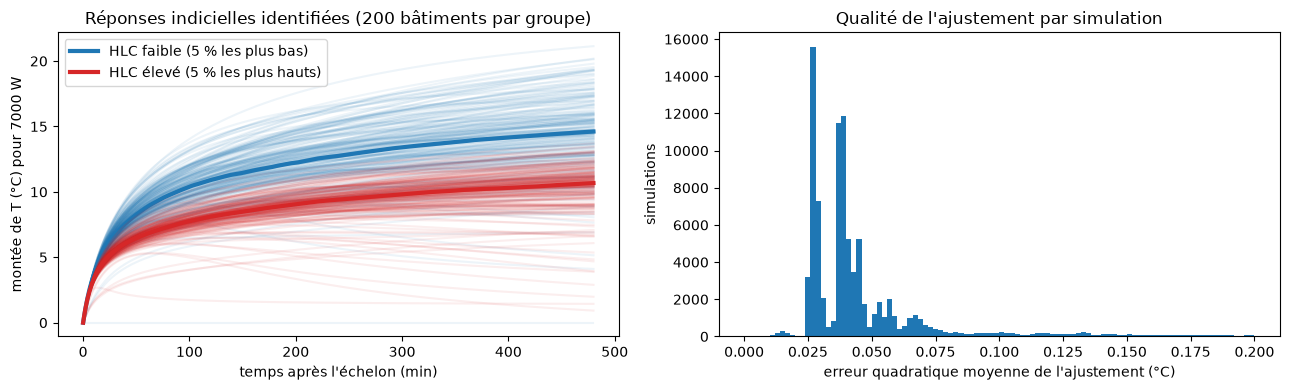

In [5]:
t = np.arange(0, 481)
taus = np.array(MODE_TAUS_MIN)
g_cols = [f"gain_u_tau{int(x)}" for x in MODE_TAUS_MIN]
q = yv.loc[heat, "HLC"].quantile([0.05, 0.95])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, mask, color in [("HLC faible (5 % les plus bas)", yv["HLC"] <= q.iloc[0], "tab:blue"),
                           ("HLC élevé (5 % les plus hauts)", yv["HLC"] >= q.iloc[1], "tab:red")]:
    G = Xv.loc[mask & heat, g_cols].to_numpy()[:200]
    S = G @ (1 - np.exp(-t[None, :] / taus[:, None]))
    axes[0].plot(t, S.T, color=color, alpha=0.08)
    axes[0].plot(t, np.median(S, 0), color=color, lw=3, label=label)
axes[0].set(xlabel="temps après l'échelon (min)", ylabel="montée de T (°C) pour 7000 W",
            title="Réponses indicielles identifiées (200 bâtiments par groupe)")
axes[0].legend()
axes[1].hist(Xv.loc[heat, "fit_rmse"], bins=100, range=(0, 0.2))
axes[1].set(xlabel="erreur quadratique moyenne de l'ajustement (°C)", ylabel="simulations",
            title="Qualité de l'ajustement par simulation")
plt.tight_layout()
print(f"erreur d'ajustement médiane : {Xv.loc[heat, 'fit_rmse'].median():.3f} °C")

In [6]:
corr_table(Xv[list(STEP_FEATURE_NAMES)], targets_t).style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf
gain_u_tau5,0.17,0.16,0.08,-0.03,0.12,0.02
gain_u_tau15,-0.07,-0.07,-0.03,0.02,-0.04,-0.00
gain_u_tau45,-0.25,-0.22,-0.13,0.05,-0.16,-0.01
gain_u_tau135,-0.02,-0.04,0.03,-0.01,-0.07,-0.03
gain_u_tau400,-0.14,-0.11,-0.09,0.00,-0.03,-0.02
gain_u_tau1200,-0.11,-0.05,-0.12,0.01,0.06,0.01
free_tau5,-0.02,0.00,-0.04,0.01,0.02,0.01
free_tau15,0.05,0.02,0.06,-0.02,-0.01,-0.01
free_tau45,-0.04,-0.01,-0.06,0.02,0.03,0.02
free_tau135,0.00,-0.02,0.04,0.00,-0.07,-0.01


**Lecture.**
- Le modèle colle très bien aux courbes (quelques centièmes de degré) : l'identification fonctionne.
- Les bâtiments à faible HLC montent plus haut, comme attendu physiquement ($\Delta T \approx P/\text{HLC}$ en régime établi), mais les deux nuages se recouvrent largement.
- Les corrélations augmentent (jusqu'à 0,4 pour le HLC avec `step_60min`) mais restent modérées, et quasi nulles pour τ_b et τ_inf.

## 4. Ajustement et résultats sur la validation

`thermal_id.baseline.run` : standardisation des descripteurs (statistiques du train), puis moindres carrés sur les cibles normalisées (H_b, log τ). Deux variantes : degré 1 (37 coefficients par cible) et degré 2 (avec les produits de descripteurs deux à deux, 703 coefficients par cible). Les équations normales sont accumulées fichier par fichier. Le HLC prédit est la somme HLC_mit + HLC_ext.

In [7]:
results = run(PROCESSED, RESULTS)
rows = {"moyenne du train": results["mean_predictor"],
        "linéaire degré 1": results["linear_deg1"]["val"],
        "linéaire degré 2": results["linear_deg2"]["val"]}
mape = pd.DataFrame({k: {t: v[t]["mape"] for t in RAW_TARGETS} for k, v in rows.items()}).T
r2 = pd.DataFrame({k: {t: v[t]["r2"] for t in RAW_TARGETS} for k, v in rows.items()}).T
mae = pd.DataFrame({k: {t: v[t]["mae"] for t in RAW_TARGETS} for k, v in rows.items()}).T
display(mape.style.format("{:.2f}").set_caption("MAPE validation (%)"))
display(r2.style.format("{:.3f}").set_caption("R² validation"))
display(mae.style.format("{:.2f}").set_caption("MAE validation (W/K pour HLC et H_b, h pour les tau)"))

descripteurs : 2.6 s


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,11.15,18.94,12.79,16.05,14.21,19.07
linéaire degré 1,9.16,16.30,11.90,15.87,13.12,18.86
linéaire degré 2,8.58,16.01,10.80,15.40,12.61,18.46


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,-0.000,-0.000,-0.000,-0.009,-0.007,-0.012
linéaire degré 1,0.305,0.229,0.120,0.011,0.141,0.010
linéaire degré 2,0.386,0.253,0.263,0.065,0.206,0.048


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
moyenne du train,25.32,21.38,13.83,7.92,1.56,5.85
linéaire degré 1,20.90,18.54,12.91,7.84,1.45,5.79
linéaire degré 2,19.61,18.24,11.75,7.62,1.39,5.68


**Lecture.** Le gain sur la simple moyenne est réel mais modeste : le MAPE du HLC passe de 11,2 % à 8,6 %, le R² plafonne à 0,39. τ_b et τ_inf ne sont pratiquement pas prédits (R² ≤ 0,07). Le degré 2 apporte un peu : la relation descripteurs → cibles n'est pas linéaire.

## 5. Où le modèle se trompe

Prédit contre réel pour le modèle de degré 2, puis erreur par famille d'excitation.

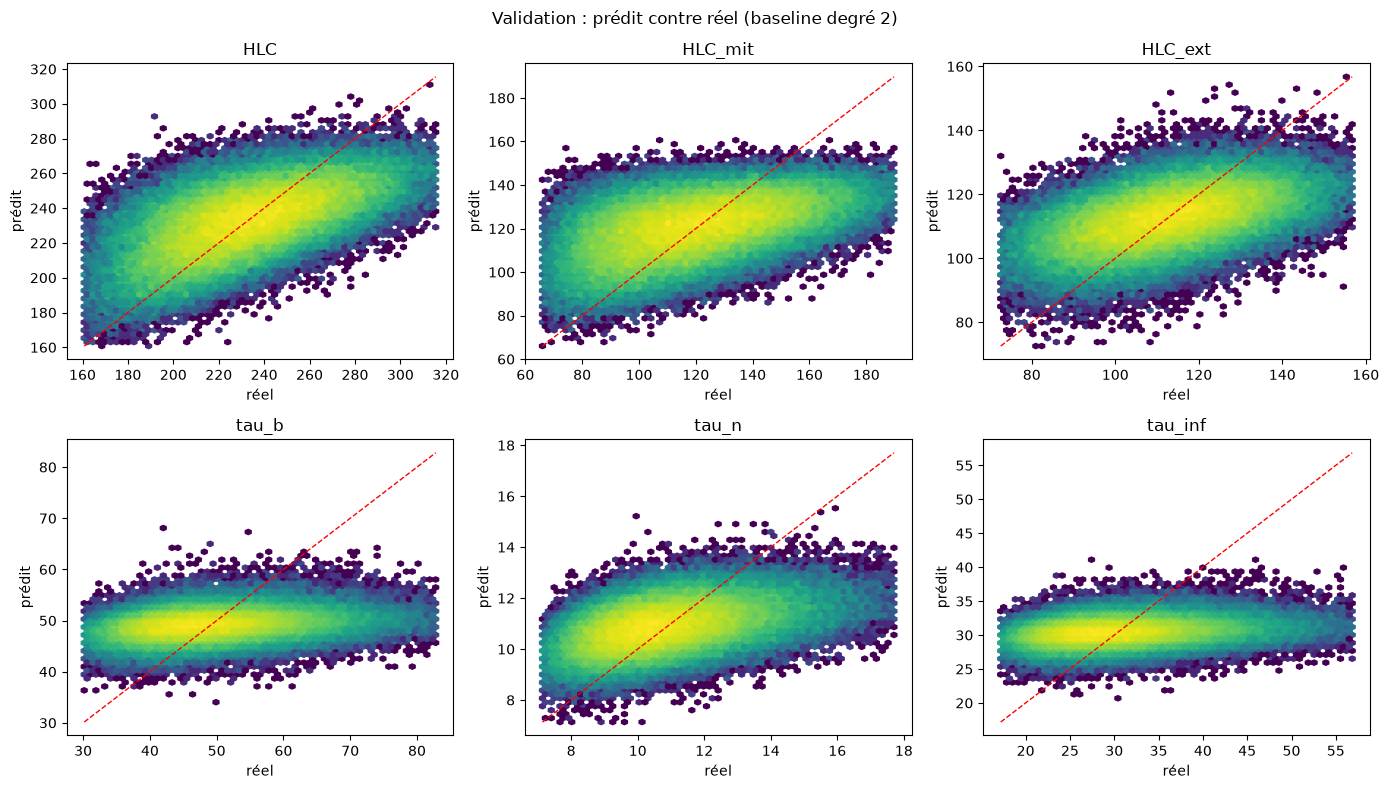

In [8]:
saved = torch.load(RESULTS / "baseline_deg2.pt", weights_only=True)
model = LinearBaseline(**saved["model"])
pred = norm.inverse(model.predict(val["X"])).numpy()
true = val["y"].numpy()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (i, name) in zip(axes.ravel(), enumerate(RAW_TARGETS)):
    lo, hi = np.percentile(true[:, i], [0.5, 99.5])
    ax.hexbin(true[:, i], pred[:, i], gridsize=60, extent=(lo, hi, lo, hi), mincnt=1, bins="log", cmap="viridis")
    ax.plot([lo, hi], [lo, hi], "r--", lw=1)
    ax.set(title=name, xlabel="réel", ylabel="prédit")
plt.suptitle("Validation : prédit contre réel (baseline degré 2)")
plt.tight_layout()

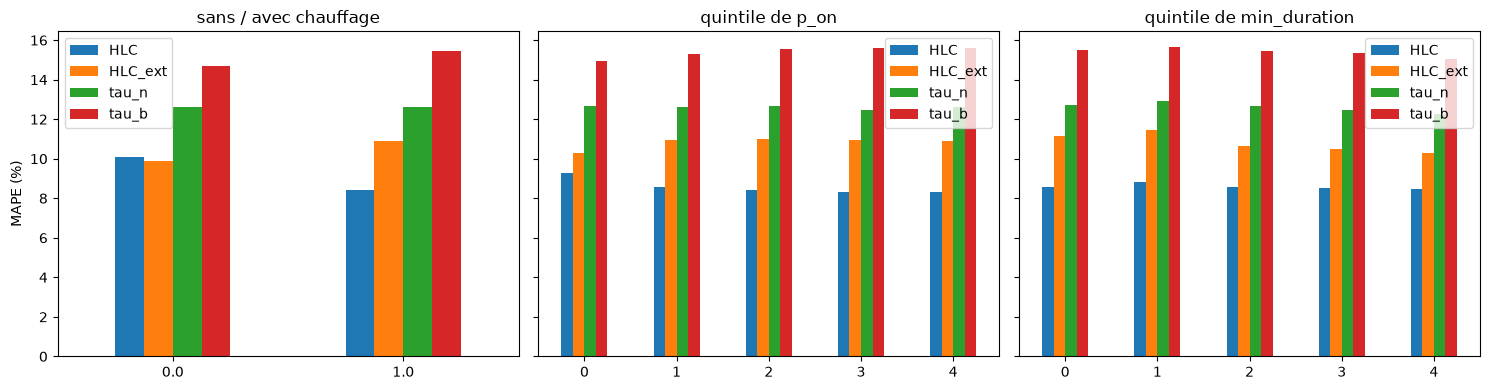

In [9]:
d2 = results["linear_deg2"]
groups = {"sans / avec chauffage": d2["val_mape_no_heat_vs_heat"],
          "quintile de p_on": d2["val_mape_by_p_on_quintile"],
          "quintile de min_duration": d2["val_mape_by_min_duration_quintile"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, g) in zip(axes, groups.items()):
    pd.DataFrame(g).T.drop(columns="n")[["HLC", "HLC_ext", "tau_n", "tau_b"]].plot.bar(ax=ax, rot=0)
    ax.set(title=title, ylabel="MAPE (%)")
plt.tight_layout()

**Lecture.**
- Les nuages sont « aplatis » vers la moyenne : le modèle prédit peu de variation, signe d'une information faible dans les descripteurs.
- L'erreur ne dépend presque pas du scénario (rythme, quantité de chauffage). Même les simulations sans chauffage ne sont que légèrement moins bien prédites : la difficulté ne vient pas d'un type d'excitation particulier.

## 6. Contrôle : quel plafond à signal U fixé ?

Les descripteurs sont-ils en cause, ou le problème est-il difficile en lui-même ? Test : on prend toutes les simulations qui partagent **le même signal U** (le plus fréquent parmi les signaux chauffés de la validation). La seule différence entre elles est alors le bâtiment. On régresse les cibles sur la courbe complète (48 points) avec moitié ajustement / moitié test.

In [10]:
b17 = CompactBatch.load(PROCESSED / "batch_17.pt")
uniq, gid, counts = torch.unique(b17.U_on, dim=0, return_inverse=True, return_counts=True)
counts = counts.where(uniq.sum(1) > 0, torch.zeros_like(counts))
m = gid == counts.argmax()
T = b17.T[m].double(); y = b17.y[m].double()
tg = torch.cat([y[:, :3], y[:, 3:].log()], 1)
X = (T[:, ::10] - T[:, :1])[:, 1:]
perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
X, tg = X[perm], tg[perm]
h = len(X) // 2
A = torch.cat([torch.ones(len(X), 1, dtype=torch.float64), (X - X[:h].mean(0)) / X[:h].std(0)], 1)
W = torch.linalg.lstsq(A[:h], tg[:h]).solution
res = A[h:] @ W - tg[h:]
r2_fixed = 1 - (res**2).sum(0) / ((tg[h:] - tg[h:].mean(0)) ** 2).sum(0)
print(f"{int(m.sum())} simulations avec le même signal U (part chauffée {b17.U_on[m][0].float().mean():.2f})")
pd.Series(r2_fixed.numpy(), index=targets_t.columns, name="R² à U fixé").round(3)

744 simulations avec le même signal U (part chauffée 0.65)


HLC            0.508
HLC_mit        0.236
HLC_ext        0.507
log tau_b      0.038
log tau_n      0.277
log tau_inf   -0.050
Name: R² à U fixé, dtype: float64

**Lecture.** Même quand le scénario de chauffage est identique pour tous et que seule la réponse du bâtiment varie, une régression linéaire sur la courbe complète n'explique qu'environ la moitié de la variance du HLC et presque rien de τ_b et τ_inf. Une partie de la difficulté est **intrinsèque** : 8 h d'observation sont courtes face à des constantes de temps de l'ordre de 10 à 50 h, et des bâtiments différents produisent des courbes presque identiques (non-injectivité, voir EDA section 4).

## 7. Conclusions

| Constat | Conséquence pour la suite |
|---|---|
| Descripteurs bruts dominés par le scénario U | Le modèle doit apprendre à « séparer » U et réponse du bâtiment : il reçoit les deux séries en entrée |
| L'identification par réponse indicielle aide (R² HLC 0,28 → 0,39) | La logique physique (réponse à un échelon) est la bonne ; un Conv1D peut l'apprendre comme un filtre |
| Degré 2 > degré 1 | Relation non linéaire : un réseau est justifié |
| Plafond limité même à U fixé | τ_b et τ_inf faiblement identifiables sur 8 h ; à présenter honnêtement, pas comme un échec du modèle |

**Barre à battre pour le réseau (validation)** : MAPE HLC 8,6 %, HLC_mit 16,0 %, HLC_ext 10,8 %, τ_b 15,4 %, τ_n 12,6 %, τ_inf 18,5 %.

**Température arrondie à 0,01 °C.** Ce notebook utilise $T_{int}$ à sa précision de stockage. Relancée sur les données arrondies comme dans l'énoncé (`uv run python -m thermal_id.baseline --processed-dir data/processed_t2 --out results/t2`), la baseline donne des scores identiques au centième près : ses descripteurs sont des moyennes et des ajustements sur toute la courbe, qui lissent les marches de 0,01 °C. C'est cette version qui figure dans le tableau final du notebook 4.